# **Библиотека Rasterio для обработки и анализа растровых данных**



## **Введение**

- [Rasterio](https://rasterio.readthedocs.io/) — библиотека Python для чтения, записи и анализа растровых геопространственных данных. Основанная на [GDAL](https://gdal.org), она предоставляет удобный интерфейс для работы со спутниковыми снимками, цифровыми моделями рельефа (DEM) и другими растровыми данными. Rasterio упрощает распространенные геопространственные задачи и легко интегрируется с `numpy`, `pandas` и `matplotlib`.

- Растровые данные представляют собой сетку пикселей, где каждый пиксель хранит некоторую географическую информацию — например, высоту, температуру или отражение. Rasterio обеспечивает простой доступ к этим данным, сохраняя их геопространственные характеристики.

## **В рамках данного блокнота мы обучимся:**



- Использовать библиотеку Rasterio, чтобы читать, записывать и изменять растровые данные.  
- Извлекать метаданные и выполнять операции с каналами растровых изображений.  
- Визуализировать растровые наборы данных и совмещать их с векторными объектами.  
- Выполнять различные геопространственные операции (обрезку, перепроецирование, растровую алгебру).  
- Применять Rasterio для геоаналитики, включая расчёт индексов и обработку растров для конкретных задач.

## **Установка зависимостей**


Перед началом работы с Rasterio необходимо необходимый набор библиотек:

In [ ]:
%%capture
%pip install rasterio fiona folium matplotlib mapclassify

## **Импорт библиотек**



Для начала работы вам потребуется импортировать rasterio вместе с несколькими другими полезными библиотеками Python. Эти библиотеки позволят нам выполнять различные типы геопространственных операций, манипулировать массивами и визуализировать растровые данные.

In [ ]:
import rasterio
import rasterio.plot
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

* `rasterio`: Основная библиотека для чтения и записи растровых данных.
* `rasterio.plot`: Подмодуль Rasterio для построения графиков растровых данных.
* `geopandas`: Популярная библиотека для работы с векторными геопространственными данными.
* `numpy`: Эффективная библиотека для манипуляций с массивами, которая очень полезна для растровых данных.
* `matplotlib`: Стандартная библиотека для построения графиков в Python для создания визуализаций.

## **Раздел №1. Чтение растровых данных**



Для чтения растровых данных можно использовать функцию `rasterio.open()`. Эта функция создает соединение с файлом без загрузки всего набора данных в память. Это особенно полезно для больших наборов данных, таких как спутниковые изображения или высокоточные цифровые модели рельефа (DEM), поскольку они могут быть слишком большими, чтобы поместиться в память одновременно.

В этом примере мы открываем файл растровой цифровой модели рельефа (DEM) по URL:

In [ ]:
# Указываем путь к растровому файлу ЦМР (цифровая модель рельефа) на GitHub
raster_path = (
    "https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif"
)

# Открываем растровый файл с использованием библиотеки rasterio
src = rasterio.open(raster_path)

# Выводим информацию о растровом файле
print(src)

<open DatasetReader name='https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif' mode='r'>


Здесь `rasterio.open()` возвращает объект `DatasetReader`, который позволяет нам взаимодействовать с файлом растровых данных. Этот объект предоставляет доступ к различным атрибутам и методам для чтения метаданных растров и значений пикселей.


## **Раздел №2. Получение основной информации о растре**



После открытия файла растра вы можете получить метаданные о растре, включая его систему координат (CRS), разрешение, границы, количество каналов и тип данных. Вот как можно получить доступ к некоторым из основных свойств:

### **Доступ к метаданным и информации о файле**


#### 1. **Имя файла:** Атрибут `name` дает вам путь к файлу или URL открытого растра.


In [ ]:
src.name

'https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif'

#### 2. **Режим файла:** Атрибут `mode` показывает, как был открыт файл. Например, растр может быть открыт в режиме только для чтения (`'r'`) или для записи (`'w'`).


In [ ]:
src.mode

'r'

#### 3. **Метаданные растра:** Атрибут `meta` предоставляет ключевую информацию о растре, такую как его ширина, высота, CRS, количество каналов и тип данных.



In [ ]:
src.meta

{'driver': 'GTiff',
 'dtype': 'int16',
 'nodata': None,
 'width': 4269,
 'height': 3113,
 'count': 1,
 'crs': CRS.from_wkt('PROJCS["WGS 84 / Pseudo-Mercator",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Mercator_1SP"],PARAMETER["central_meridian",0],PARAMETER["scale_factor",1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],EXTENSION["PROJ4","+proj=merc +a=6378137 +b=6378137 +lat_ts=0 +lon_0=0 +x_0=0 +y_0=0 +k=1 +units=m +nadgrids=@null +wktext +no_defs"],AUTHORITY["EPSG","3857"]]'),
 'transform': Affine(90.0, 0.0, -13442488.3428,
        0.0, -89.99579177642138, 4668371.5775)}

- Для данного набора параметров, конкретизируем их значения:

  - **driver**: 'GTiff' - это формат файла, используемый для хранения растра. В данном случае, это GeoTIFF, который поддерживает геопространственные метаданные.

  - **dtype**: 'int16' - тип данных пикселей в растре. Значение 'int16' указывает на то, что каждый пиксель представлен 16-битным целым числом со знаком.

  - **nodata**: None - значение, которое используется для обозначения отсутствующих данных в растре. В данном случае, значение не задано.

  - **width**: 4269 - ширина растра в пикселях.

  - **height**: 3113 - высота растра в пикселях.

  - **count**: 1 - количество каналов (полос) в растре. Значение 1 указывает на то, что растр одноканальный.

  - **crs**: CRS.from_wkt('PROJCS["WGS 84 / Pseudo-Mercator",...') - система координат растра, определенная в формате WKT (Well-Known Text). В данном случае, это проекция Pseudo-Mercator на основе эллипсоида WGS 84, с EPSG кодом 3857.

  - **transform**: Affine(90.0, 0.0, -13442488.3428, 0.0, -89.99579177642138, 4668371.5775) - матрица аффинного преобразования, которая сопоставляет координаты пикселей с географическими координатами. Параметры матрицы интерпретируются следующим образом:
    - `a`: 90.0 - ширина пикселя в направлении x.
    - `b`: 0.0 - вращение строки (обычно ноль).
    - `c`: -13442488.3428 - x-координата верхнего левого угла верхнего левого пикселя.
    - `d`: 0.0 - вращение столбца (обычно ноль).
    - `e`: -89.99579177642138 - высота пикселя в направлении y (обычно отрицательная).
    - `f`: 4668371.5775 - y-координата верхнего левого угла верхнего левого пикселя.

#### 4. **Система координат (CRS)**: CRS описывает, как значения пикселей в 2D связаны с реальными географическими координатами (широта и долгота или проецированные координаты). Знание CRS необходимо для интерпретации данных осмысленным образом.

Чтобы получить CRS:



In [ ]:
src.crs

CRS.from_wkt('PROJCS["WGS 84 / Pseudo-Mercator",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Mercator_1SP"],PARAMETER["central_meridian",0],PARAMETER["scale_factor",1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],EXTENSION["PROJ4","+proj=merc +a=6378137 +b=6378137 +lat_ts=0 +lon_0=0 +x_0=0 +y_0=0 +k=1 +units=m +nadgrids=@null +wktext +no_defs"],AUTHORITY["EPSG","3857"]]')

#### 5. **Пространственное разрешение**:Разрешение растра относится к размеру одного пикселя в реальных единицах (например, метрах).

Вы можете получить доступ к разрешению с помощью атрибута `res`:

In [ ]:
src.res

(90.0, 89.99579177642138)

- - **90.0**: Это значение представляет ширину пикселя в направлении x, обычно измеряемую в единицах системы координат (CRS), используемой набором данных. Например, если набор данных использует CRS с единицами в метрах, это означает, что каждый пиксель имеет ширину 90 метров.

- - **89.99579177642138**: Это значение представляет высоту пикселя в направлении y. Аналогично направлению x, это значение также выражено в единицах CRS. Небольшое отличие от 90.0 может быть вызвано различными факторами, такими как используемая проекция или конкретная реализация системы координат растра.

#### 6. **Размеры (ширина и высота)**: Ширина и высота указывают количество пикселей по оси x и y соответственно:

In [ ]:
src.width

4269

In [ ]:
src.height

3113

#### 7. **Границы**: Атрибут `bounds` предоставляет географический охват набора данных растра, представленный координатами краев растра (слева, снизу, справа, сверху):


In [ ]:
src.bounds

BoundingBox(left=-13442488.3428, bottom=4388214.6777, right=-13058278.3428, top=4668371.5775)

#### 8. **Типы данных**: Атрибут `dtypes` содержит тип данных каждого значения пикселя (например, `uint8`, `int16`, `float32`). Это важно при выполнении математических операций с растровыми данными.




In [ ]:
src.dtypes

('int16',)

#### 9. **Параметры матрицы аффинного преобразования**





[Аффинное преобразование](https://en.wikipedia.org/wiki/Affine_transformation) представляет собой отображение плоскости или пространства в себя, при котором сохраняются параллельность линий и отношение отрезков на параллельных линиях. Матрица аффинного преобразования сопоставляет координаты пикселей с географическими координатами. Это преобразование необходимо для понимания того, как расположение пикселей связано с реальными координатами.


In [ ]:
src.transform

Affine(90.0, 0.0, -13442488.3428,
       0.0, -89.99579177642138, 4668371.5775)

Матрица преобразования состоит из шести параметров, которые контролируют масштабирование, перемещение и вращение растра. Большинство растров не будут иметь вращения (параметры `b` и `d` равны 0), но преобразование будет включать размер пикселя (параметры `a` и `e`) и географические координаты верхнего левого пикселя (параметры `c` и `f`).

- `a`: ширина пикселя в направлении x
- `b`: вращение строки (обычно ноль)
- `c`: x-координата верхнего левого угла верхнего левого пикселя
- `d`: вращение столбца (обычно ноль)
- `e`: высота пикселя в направлении y (обычно отрицательная)
- `f`: y-координата верхнего левого угла верхнего левого пикселя

Параметры `a` и `e` представляют собой ширину и высоту пикселя соответственно, а параметры `c` и `f` - координаты верхнего левого угла растра. Остальные коэффициенты используются для вращения и сдвига.

## **Раздел №3. Визуализация растровых данных**



Rasterio может легко интегрироваться с `matplotlib` для визуализации растров. Функция `rasterio.plot.show()` является самым простым способом отображения растрового изображения, и по умолчанию она показывает первый канал растра.





### **Базовый метод для отображения растра**



Здесь мы строим график растра с использованием метода `rasterio.plot.show()`:

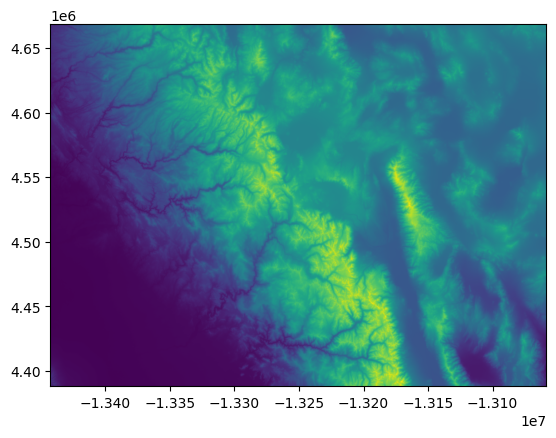

<Axes: >

In [ ]:
rasterio.plot.show(src)

Эта функция автоматически обрабатывает геореференцирование растра, обеспечивая отображение растра в его правильном географическом положении.



### **Отображение конкретного канала**

Rasterio поддерживает многоканальные растры (например, спутниковые изображения). Чтобы отобразить конкретный канал, можно передать номер канала в виде кортежа вместе с объектом набора данных. Здесь мы строим график первого канала:



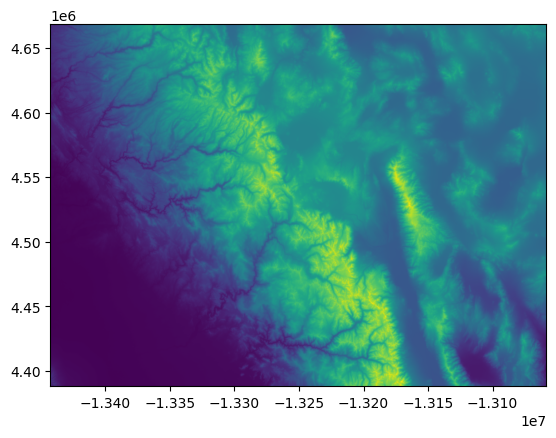

<Axes: >

In [ ]:
# Используем функцию show из модуля rasterio.plot для отображения растра
# Передаем кортеж, содержащий объект растра (src) и номер канала (1)
# Это отобразит первый канал растра
rasterio.plot.show((src, 1))

В геопространственных данных каналы относятся к различным слоям данных (например, красный, зеленый, синий, инфракрасный для спутниковых изображений). Индекс канала в `rasterio` начинается с 1, поэтому канал 1 относится к первому каналу в наборе данных.



### **Настройка графиков**

Вы можете дополнительно улучшить свои графики с помощью цветовых карт и заголовков. Вот пример, который настраивает цветовую карту на "terrain" и добавляет заголовок к графику:



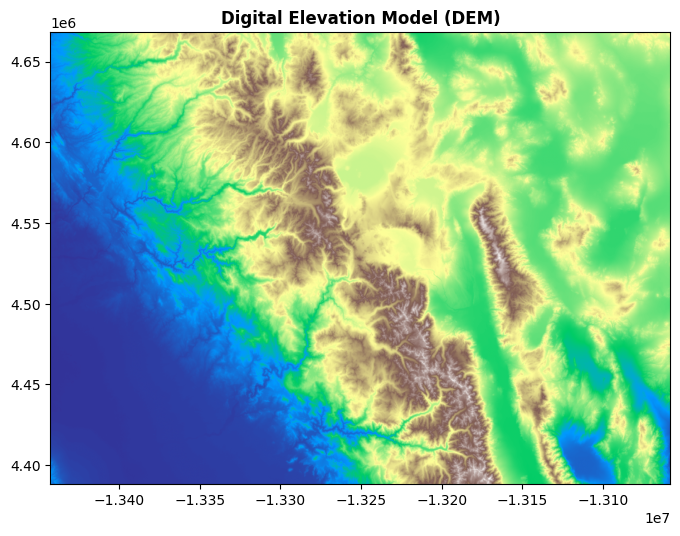

In [ ]:
# Создаем новую фигуру и ось с размером 8x8
fig, ax = plt.subplots(figsize=(8, 8))

# Отображаем растр с использованием цветовой карты "terrain", добавляем заголовок "Digital Elevation Model (DEM)"
rasterio.plot.show(src, cmap="terrain", ax=ax, title="Digital Elevation Model (DEM)")

# Отображаем созданный график
plt.show()

### **Наложение векторного слоя поверх растрового изображения**



В геопространственном анализе часто накладывают векторные данные поверх растровых изображений для предоставления дополнительного контекста. Векторные данные часто представляют границы, дороги или другие объекты, в то время как растровые данные представляют непрерывные поля, такие как высота или температура. Например, мы можем захотеть построить векторную границу поверх цифровой модели рельефа (DEM) растра. В этом примере мы загружаем файл GeoJSON, содержащий векторные данные, обеспечиваем его совпадение с CRS растра и строим его поверх DEM.

Сначала давайте загрузим векторные данные и перепроектируем их для соответствия CRS растра:



In [ ]:
# Указываем путь к файлу с векторными даными

dem_bounds = (
    "https://github.com/opengeos/datasets/releases/download/places/dem_bounds.geojson"
)

# Считываем GeoJSON файл и создаем GeoDataFrame
gdf = gpd.read_file(dem_bounds)

# Преобразуем GeoDataFrame в ту же систему координат, что и растр src
gdf = gdf.to_crs(src.crs)



Векторные данные считываются с помощью `geopandas.read_file()`, а затем мы обеспечиваем совпадение CRS векторных данных с CRS растра с помощью `gdf.to_crs(src.crs)`. Этот шаг очень важен для обеспечения правильного взаимодействия между растровыми и векторными слоями.

Далее мы можем построить график DEM растра и наложить на него векторные данные:



<Axes: title={'center': 'Digital Elevation Model (DEM)'}>

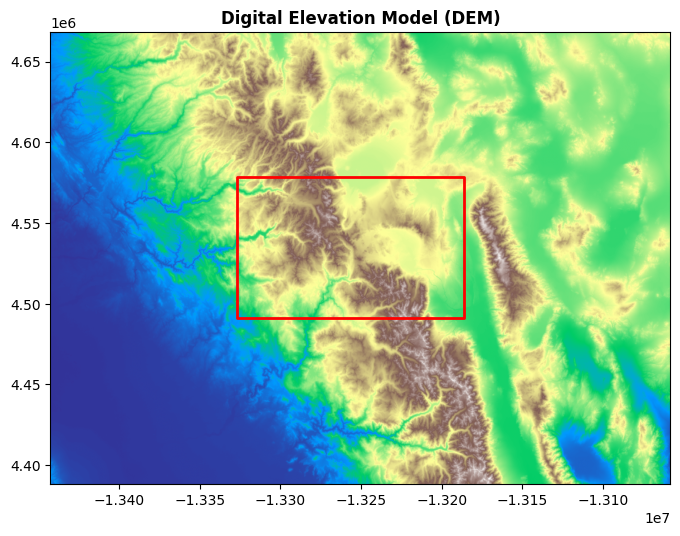

In [ ]:
# Создаем новую фигуру и ось с размером 8x8
fig, ax = plt.subplots(figsize=(8, 8))

# Отображаем растр с использованием цветовой карты "terrain", добавляем заголовок "Digital Elevation Model (DEM)"
rasterio.plot.show(src, cmap="terrain", ax=ax, title="Digital Elevation Model (DEM)")

# Накладываем границы из GeoDataFrame на растр, используя красный цвет для границ и без заливки
gdf.plot(ax=ax, edgecolor="red", facecolor="none", lw=2)

В этом блоке мы используем `rasterio.plot.show()` для построения растровых данных, используя цветовую карту `"terrain"` для визуализации изменений высоты. Затем мы накладываем векторную границу поверх с помощью `gdf.plot()`. Параметр `edgecolor='red'` устанавливает цвет границы на красный, а `facecolor='none'` обеспечивает прозрачность внутренней части границы, что облегчает просмотр растра под ней.



### **Добавление цветовой карты и информативной легенды**

При визуализации растровых данных цветовые карты помогают сопоставлять значения пикселей с цветами, в то время как цветовые шкалы предоставляют эталонную шкалу для интерпретации значений пикселей. В этом примере мы построим первый канал DEM с пользовательской цветовой картой (`'terrain'`) и добавим цветовую шкалу для лучшего понимания значений высоты.

Давайте прочитаем первый канал и построим его с цветовой картой:


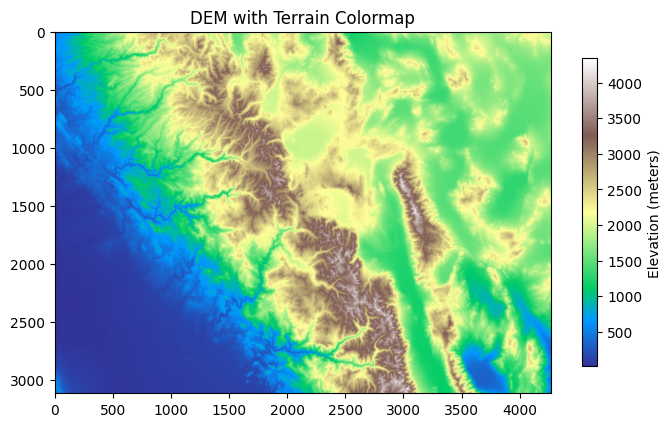

In [ ]:
# Считываем первый канал (band) из растра src
elev_band = src.read(1)

# Создаем новую фигуру с размером 8x8 дюймов
plt.figure(figsize=(8, 8))

# Отображаем данные первой полосы с использованием цветовой карты "terrain"
plt.imshow(elev_band, cmap="terrain")

# Добавляем цветовую шкалу с меткой "Elevation (meters)" и уменьшаем ее размер до 50%
plt.colorbar(label="Elevation (meters)", shrink=0.5)

# Устанавливаем заголовок графика "DEM with Terrain Colormap"
plt.title("DEM with Terrain Colormap")

# Отображаем созданный график
plt.show()

Здесь мы читаем первый канал растра с помощью `src.read(1)`, что соответствует данным высоты DEM. Функция `plt.imshow()` отображает растр с использованием цветовой карты `'terrain'`. Мы также добавляем цветовую шкалу с помощью `plt.colorbar()`, чтобы предоставить эталон для интерпретации значений высоты, а опция `shrink=0.5` масштабирует цветовую шкалу для соответствия фигуре.

График показывает DEM с цветовой картой, которая выделяет различные высоты с использованием цветовой схемы `'terrain'`. Цветовая шкала предоставляет четкую шкалу для понимания того, как распределены значения пикселей (представляющие высоту в метрах). График также имеет заголовок для предоставления дополнительного контекста.

### **Трехмерная визуализация ЦМР**

### **Используя [leafmap](https://leafmap.org/notebooks/54_plot_raster/) (не подходит для Colab)**

In [ ]:
%%capture
!pip install leafmap

In [ ]:
import os
import leafmap

leafmap.plot_raster_3d(raster_path, factor=2, cmap='magma', background='gray')

This function is not supported in Google Colab.


![Текст ссылки](https://i.imgur.com/UQDbV2G.gif)

## **Раздел №4. Обработка многоканальных растров. Формирование композитов**



Растровые наборы данных часто состоят из нескольких каналов, каждый из которых захватывает различную часть электромагнитного спектра. Например, спутниковые снимки могут включать в себя отдельные каналы для красного, зеленого, синего и ближнего инфракрасного (NIR) диапазонов длин волн.





### **Считывание многоканального растра**



Для начала давайте откроем многоканальный растровый набор данных с использованием библиотеки `rasterio`. После открытия файла мы можем изучить его метаданные, чтобы узнать о наборе данных:

In [ ]:
raster_path = "https://github.com/opengeos/datasets/releases/download/raster/LC09_039035_20240708_90m.tif"
src = rasterio.open(raster_path)
print(src)

<open DatasetReader name='https://github.com/opengeos/datasets/releases/download/raster/LC09_039035_20240708_90m.tif' mode='r'>


Как только файл открыт, мы можем просмотреть его метаданные, чтобы узнать больше о наборе данных:

In [ ]:
src.meta

{'driver': 'GTiff',
 'dtype': 'float32',
 'nodata': -inf,
 'width': 2485,
 'height': 2563,
 'count': 7,
 'crs': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'),
 'transform': Affine(90.0, 0.0, 582390.0,
        0.0, -90.0, 4105620.0)}



Этот набор данных содержит несколько каналов, каждый из которых соответствует определенному диапазону длин волн, как описано в таблице ниже:

| Название | Длина волны       | Описание                                        |
|----------|-------------------|-------------------------------------------------|
| SR_B1    | 0.435-0.451 мкм   | Канал 1 (ультрафиолетовый, Coastal Aerosol) отражение поверхности |
| SR_B2    | 0.452-0.512 мкм   | Канал 2 (синий) отражение поверхности           |
| SR_B3    | 0.533-0.590 мкм   | Канал 3 (зеленый) отражение поверхности         |
| SR_B4    | 0.636-0.673 мкм   | Канал 4 (красный) отражение поверхности         |
| SR_B5    | 0.851-0.879 мкм   | Канал 5 (ближний инфракрасный) отражение поверхности |
| SR_B6    | 1.566-1.651 мкм   | Канал 6 (коротковолновый инфракрасный 1) отражение поверхности |
| SR_B7    | 2.107-2.294 мкм   | Канал 7 (коротковолновый инфракрасный 2) отражение поверхности |

Для удобства давайте определим список названий каналов, понятных человеку:

In [ ]:
band_names = ["Coastal Aerosol", "Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"]

Мы можем визуализировать отдельный канал (например, канал 5 - NIR), используя функции построения графиков в rasterio:

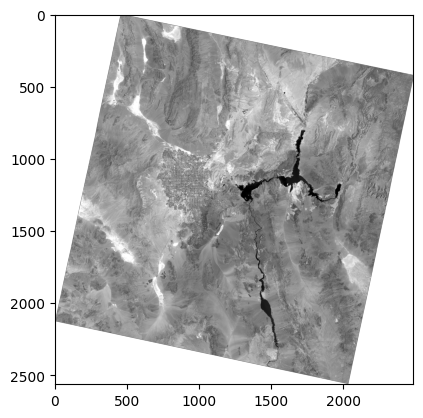

In [ ]:
plt.imshow(src.read(5), vmin=0, vmax=0.5, cmap='gray')

### **Визуализация каждого канала на отдельном подграфике**

Чтобы визуализировать все каналы вместе, мы можем создать несколько графиков на одной фигуре, отображая каждый канал с соответствующим названием:



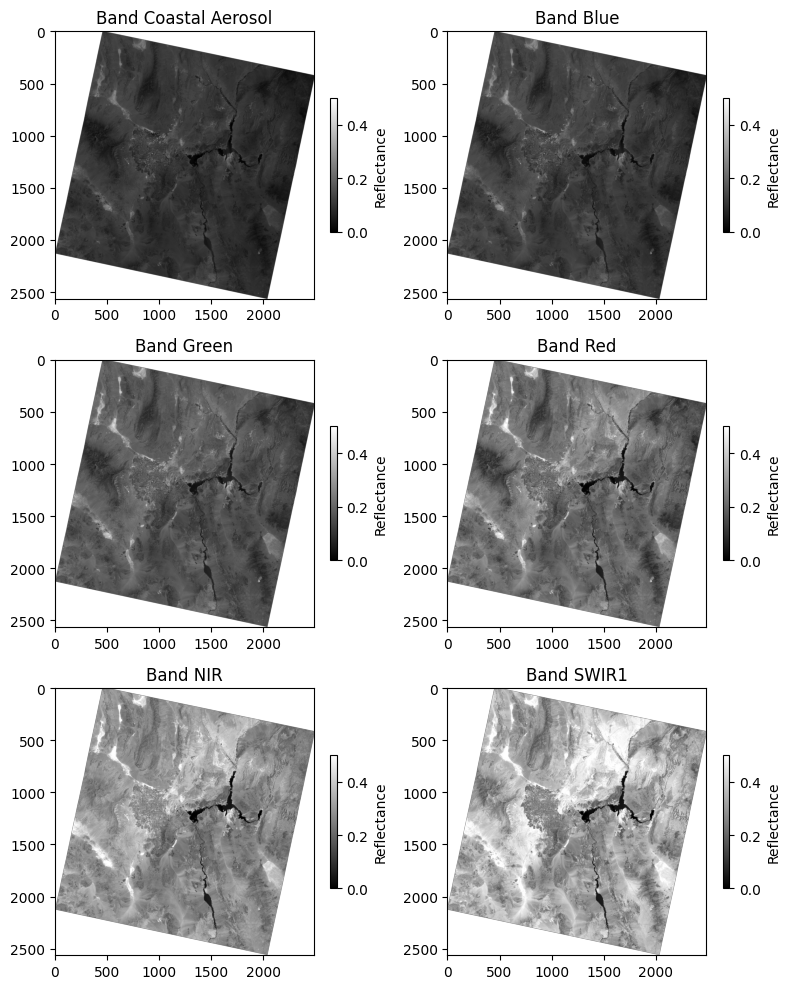

In [ ]:
# Создаем фигуру с 3 строками и 2 столбцами подграфиков, размером 8x10 дюймов
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 10))

# Преобразуем двумерный массив осей (областей) в одномерный для удобства итерации
axes = axes.flatten()

# Итерируем по всем полосам растра, начиная со второй (индекс 1)
for band in range(1, src.count):
    # Считываем текущий канал
    data = src.read(band)

    # Выбираем соответствующую ось (область построения) для текущего канала
    ax = axes[band - 1]

    # Отображаем данные канала с использованием серой цветовой карты, устанавливая минимальное и максимальное значения
    im = ax.imshow(data, cmap="gray", vmin=0, vmax=0.5)

    # Устанавливаем заголовок для текущего канала, используя соответствующее имя из списка band_names
    ax.set_title(f"Band {band_names[band - 1]}")

    # Добавляем цветовую шкалу к текущему подграфику с меткой "Reflectance" и уменьшаем ее размер до 50%
    fig.colorbar(im, ax=ax, label="Reflectance", shrink=0.5)

# Настраиваем компоновку подграфиков для оптимального использования пространства
plt.tight_layout()

# Отображаем созданный график
plt.show()

### **Формирование композита из комбинации каналов**

Мы можем объединить несколько каналов в одно изображение, поместив их в отдельный массив. Например, мы поместим каналы NIR, Red и Green в один массив:



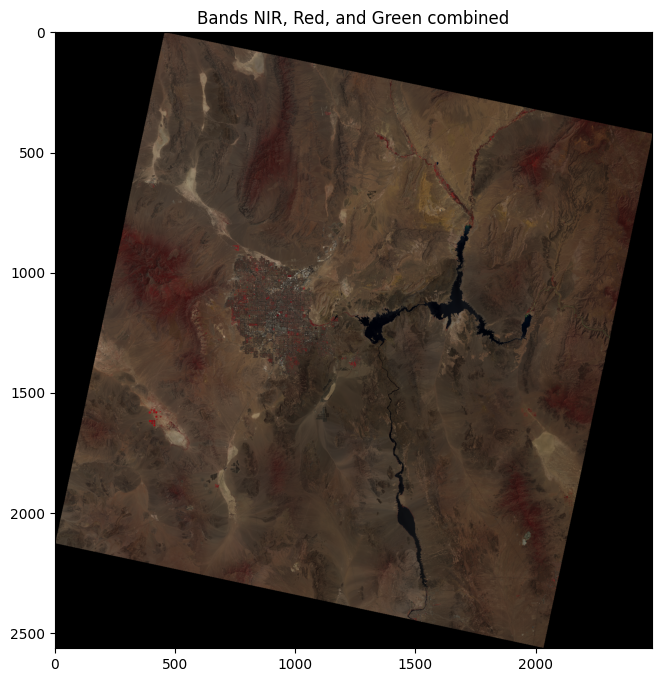

In [ ]:
# Считываем пятый канал (NIR) из растра src
nir_band = src.read(5)

# Читаем четвертый канал (красный) из растра src
red_band = src.read(4)

# Читаем третий канал (зеленый) из растра src
green_band = src.read(3)

# Объединяем каналы в один массив, используя метод np.dstack,
# и ограничиваем значения в каждом канале от 0 до 1
rgb = np.dstack((nir_band, red_band, green_band)).clip(0, 1)

# Создаем новую фигуру с размером 8x8 дюймов
plt.figure(figsize=(8, 8))

# Отображаем полученный композит (псевдоцветное изображение)
plt.imshow(rgb)

# Устанавливаем заголовок графика
plt.title("Bands NIR, Red, and Green combined")

# Отображаем созданный график
plt.show()

### **Математическая обработка каналов (расчет NDVI)**







Выполним расчет Нормализованного Разностного Индекса Растительности (NDVI), который является индикатором здоровья растительности.

NDVI рассчитывается как:

- NDVI = (NIR - Red) / (NIR + Red)

Мы можем вычислить и отобразить NDVI следующим образом:

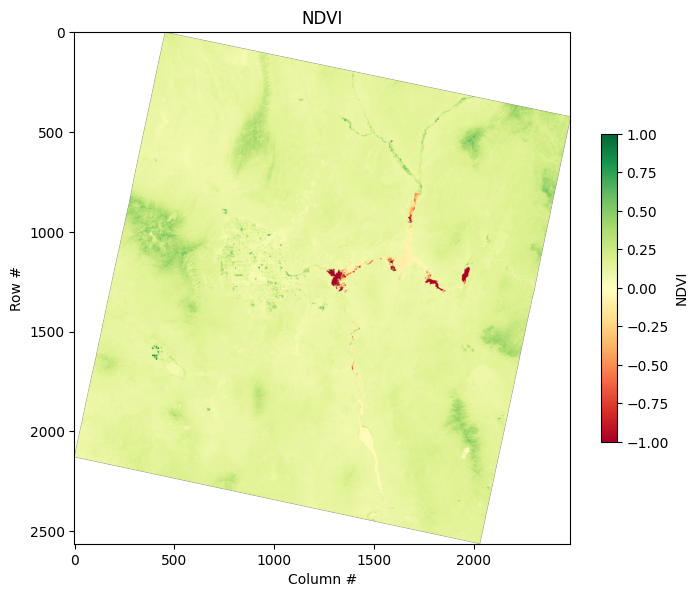

In [ ]:
# Расчет NDVI: NDVI = (NIR - Red) / (NIR + Red)
ndvi = (nir_band - red_band) / (nir_band + red_band)

# Ограничиваем значения NDVI от -1 до 1
ndvi = ndvi.clip(-1, 1)

# Создаем новую фигуру с размером 8x8 дюймов
plt.figure(figsize=(8, 8))

# Отображаем NDVI с использованием цветовой карты RdYlGn, устанавливая минимальное и максимальное значения
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)

# Добавляем цветовую шкалу с меткой "NDVI" и уменьшаем ее размер до 50%
plt.colorbar(label="NDVI", shrink=0.5)

# Устанавливаем заголовок графика
plt.title("NDVI")

# Добавляем подпись для оси X
plt.xlabel("Column #")

# Добавляем подпись для оси Y
plt.ylabel("Row #")

# Отображаем созданный график
plt.show()

#### Таблица диапазонов NDVI и их интерпретация

| **Диапазон NDVI** | **Интерпретация**                                                                     |
|-------------------|-------|
| от -1.0 до -0.1   | Затопленная или плотно увлажнённая поверхность (например, вода, болота, лёд, тени)     |
| от -0.1 до 0.2    | Малое содержание растительности (голая почва, застроенные территории, снежный покров) |
| от 0.2 до 0.4     | Слабая растительность (тонкий травяной покров, редкие травы)                          |
| от 0.4 до 0.6     | Умеренная растительность (посевы на ранней стадии, луга)                              |
| от 0.6 до 0.8     | Хорошее развитие растительности (густые травы, хорошо развивающиеся посевы)           |
| от 0.8 до 1.0     | Очень плотная растительность (зрелые леса, интенсивные сельскохозяйственные посевы)    |

## **Раздел №5. Сохранение растровых данных**



После обработки растровых данных (например, вычисления NDVI), вы можете захотеть сохранить результаты в новый файл. Используя `rasterio`, мы можем записать данные обратно в файл GeoTIFF.

Сначала мы просматриваем и обновляем профиль (метаданные) для выходного файла:



In [ ]:
# Открываем растр по указанному пути в контекстном менеджере
with rasterio.open(raster_path) as src:
    # Получаем профиль растра, который содержит метаданные
    profile = src.profile

# Выводим профиль растра на экран
print(profile)

{'driver': 'GTiff', 'dtype': 'float32', 'nodata': -inf, 'width': 2485, 'height': 2563, 'count': 7, 'crs': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'), 'transform': Affine(90.0, 0.0, 582390.0,
       0.0, -90.0, 4105620.0), 'blockxsize': 512, 'blockysize': 512, 'tiled': True, 'compress': 'deflate', 'interleave': 'pixel'}



Затем мы корректируем профиль, чтобы он соответствовал измененному набору данных (например, NDVI):



In [ ]:
# Обновляем профиль растра, устанавливая тип данных на float32, количество полос на 1 и сжатие LZW
profile.update(dtype=rasterio.float32, count=1, compress="lzw")

# Выводим обновленный профиль растра на экран
print(profile)

{'driver': 'GTiff', 'dtype': 'float32', 'nodata': -inf, 'width': 2485, 'height': 2563, 'count': 1, 'crs': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'), 'transform': Affine(90.0, 0.0, 582390.0,
       0.0, -90.0, 4105620.0), 'blockxsize': 512, 'blockysize': 512, 'tiled': True, 'compress': 'lzw', 'interleave': 'pixel'}


Наконец, мы записываем данные NDVI в новый файл:


In [ ]:
# Указываем путь к выходному файлу растра с именем "ndvi.tif"
output_raster_path = "ndvi.tif"

# Открываем файл для записи с использованием параметров профиля
with rasterio.open(output_raster_path, "w", **profile) as dst:
    # Записываем данные NDVI в первый канал выходного растра
    dst.write(ndvi, 1)

# Выводим сообщение о том, что данные растра были записаны в указанный файл
print(f"Растровые данные были записаны в файл: {output_raster_path}")

Растровые данные были записаны в файл: ndvi.tif


## **Раздел №6. Обрезка растров**



Чтобы извлечь подмножество растровых данных, мы можем использовать либо списковые срезы, либо географические границы.

Сначала давайте откроем образец растрового набора данных:


In [ ]:
# Открываем растр по указанному пути
src = rasterio.open(raster_path)

# Считываем данные из открытого растра
data = src.read()

In [ ]:
# Выводим размерность данных растра
data.shape

(7, 2563, 2485)

Затем давайте обрежем часть растровых данных с использованием спискового среза:



In [ ]:
# Открываем растровый файл для чтения используя библиотеку rasterio
src = rasterio.open(raster_path)

# Загружаем все данные из растрового файла в многомерный массив
data = src.read()

# Выводим размерность (shape) загруженного массива данных
data.shape

# Создаем подмножество данных, вырезая фрагмент изображения:
# - берем все каналы [:, ...]
# - строки с 900 по 1400
# - столбцы с 700 по 1200
# Также масштабируем значения, чтобы они были в диапазоне от 0 до 1
subset = data[:, 900:1400, 700:1200].clip(0, 1)

# Создаем псевдо-RGB изображение, комбинируя 5-й, 4-й и 3-й каналы
# np.dstack() объединяет массивы
rgb_subset = np.dstack((subset[5], subset[4], subset[3]))

# Выводим размерность полученного псевдо-RGB изображения
rgb_subset.shape

(500, 500, 3)

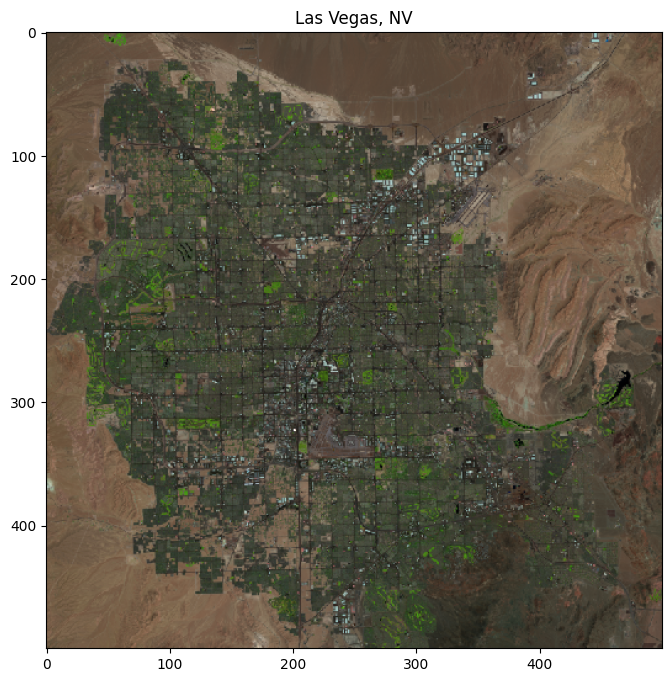

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(rgb_subset)
plt.title("Las Vegas, NV")
plt.show()

Альтернативно, мы можем использовать конкретное географическое окно для обрезки данных:



In [ ]:
# Импортируем класс Window из модуля rasterio.windows для работы с фрагментами растра
from rasterio.windows import Window
# Импортируем функцию from_bounds из модуля rasterio.transform для создания новой геопривязки
from rasterio.transform import from_bounds

# Создаем объект окна (Window), определяющий границы нужного фрагмента растра:
# - col_off=700: смещение от левого края на 700 пикселей
# - row_off=900: смещение от верхнего края на 900 пикселей
# - width=500: ширина фрагмента 500 пикселей
# - height=500: высота фрагмента 500 пикселей
window = Window(col_off=700, row_off=900, width=500, height=500)

# Вычисляем географические координаты границ выбранного окна
# используя информацию о геопривязке из исходного растра (src.transform)
window_bounds = rasterio.windows.bounds(window, src.transform)

# Создаем новую геопривязку (transform) для вырезанного фрагмента
# *window_bounds распаковывает координаты границ (left, bottom, right, top)
# window.width и window.height задают размеры в пикселях
new_transform = from_bounds(*window_bounds, window.width, window.height)



После определения окна мы записываем обрезанные данные в новый файл:



In [ ]:
with rasterio.open(
    "las_vegas.tif",
    "w",
    driver="GTiff",
    height=subset.shape[1],
    width=subset.shape[2],
    count=subset.shape[0],
    dtype=subset.dtype,
    crs=src.crs,
    transform=new_transform,
    compress="lzw",
) as dst:
    dst.write(subset)

### **Обрезка растра с использованием векторных данных**



Чтобы обрезать растр с использованием векторных данных (например, ограничивающего прямоугольника GeoJSON), мы можем использовать `rasterio.mask`. Сначала загрузим векторные данные:



In [ ]:
import rasterio.mask

In [ ]:
geojson_path = "https://github.com/opengeos/datasets/releases/download/places/las_vegas_bounds_utm.geojson"
bounds = gpd.read_file(geojson_path)

**Визуализируем растр и векторные данные вместе:**



<Axes: >

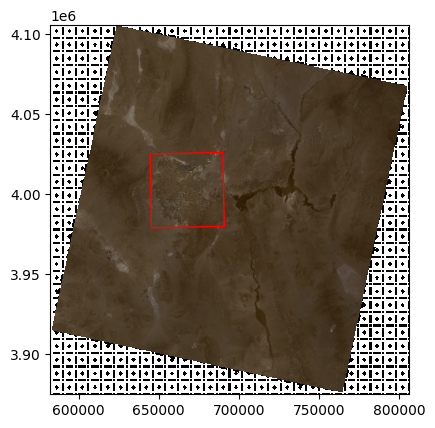

In [ ]:
fig, ax = plt.subplots()
rasterio.plot.show(src, ax=ax)
bounds.plot(ax=ax, edgecolor="red", facecolor="none")

**Затем применим маску, чтобы извлечь только область внутри векторных границ:**


In [ ]:
bounds

,geometry
0,"POLYGON ((645428.627 3978864.593, 644662.653 4..."


In [ ]:
# Извлекаем геометрии из GeoDataFrame
shapes = bounds['geometry'].tolist()
shapes

[<POLYGON ((645428.627 3978864.593, 644662.653 4024992.765, 689899.803 402586...>]

In [ ]:
# Обрезаем растр по маске, сформированной с помощью геометрий из shapes и обрезаем его по границам этих геометрий
# out_image - получаем замаскированные данные растра
# out_transform - получаем новую геопривязку для обрезанного растра

out_image, out_transform = rasterio.mask.mask(src, shapes, crop=True)

Наконец, запишем обрезанный растр в новый файл:

In [ ]:
# Копируем метаданные из исходного растра
out_meta = src.meta

# Обновляем метаданные для нового файла:
# - устанавливаем формат файла как GeoTIFF
# - обновляем высоту и ширину согласно размерам обрезанного изображения
# - задаем новую геопривязку
out_meta.update(
    {
        "driver": "GTiff",
        "height": out_image.shape[1],
        "width": out_image.shape[2],
        "transform": out_transform,
    }
)

# Создаем новый растровый файл с обновленными метаданными
# и записываем в него обрезанное изображение
with rasterio.open("las_vegas_clip.tif", "w", **out_meta) as dst:
    dst.write(out_image)

## **Раздел №7. Перепроецирование растровых данных**




Для перепроецирования растра из одной системы координат (CRS) в другую используется модуль `rasterio.warp`. В данном примере растр перепроецируется в систему координат WGS 84 (EPSG:3857) и сохраняется в новый файл.


In [ ]:
# Импортируем необходимые функции для перепроецирования растра
from rasterio.warp import calculate_default_transform, reproject, Resampling

# Задаем пути к файлам и целевую систему координат
raster_path = "las_vegas.tif"
dst_crs = "EPSG:3857"  # Целевая система координат - проекция Web Mercator
output_reprojected_path = "reprojected_raster.tif"

# Открываем исходный растр и вычисляем параметры трансформации
with rasterio.open(raster_path) as src:
    # Рассчитываем параметры трансформации для новой проекции
    transform, width, height = calculate_default_transform(
        src.crs, dst_crs, src.width, src.height, *src.bounds
    )

    # Копируем и обновляем метаданные для нового файла
    profile = src.profile
    profile.update(crs=dst_crs, transform=transform, width=width, height=height)

    # Создаем новый файл и перепроецируем данные
    with rasterio.open(output_reprojected_path, "w", **profile) as dst:
        # Перепроецируем каждый канал растра
        for i in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, i),
                destination=rasterio.band(dst, i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=dst_crs,
                resampling=Resampling.nearest,  # Используем метод ближайшего соседа
            )

# Выводим сообщение об успешном сохранении
print(f"Перепроецированный растр сохранен как: {output_reprojected_path}")

Перепроецированный растр сохранен как: reprojected_raster.tif
